# Haryana Mandi Insights
## Agricultural Price Analysis and Forecasting
### Notebook 1 — Data Cleaning and Preprocessing

---

**Course:** Advanced Data Science
**Dataset:** Haryana Mandi Agricultural Price Data (2022–2026)
**Districts:** Hissar, Jind, Kaithal, Karnal, Rewari, Sirsa



## Problem Statement

Farmers and agricultural traders in Haryana lack access to structured,
historical price information across different mandis (agricultural markets).
This makes it difficult to decide where to sell produce, which commodity
to grow, and when to enter or exit the market.

This project transforms four years of raw mandi price data into clean,
analysed and forecasted insights that can support better decision-making
for farmers, traders and agricultural policy planners.

---

## Stakeholders

| Stakeholder | Interest |
|---|---|
| Farmers | Know which mandi offers the best price for their crop |
| Agricultural Traders | Understand price trends and volatility |
| Market Planners | Identify supply gaps and price anomalies |
| Government Bodies | Monitor MSP compliance and market efficiency |

---

## Research Questions

| # | Research Question |
|---|---|
| RQ1 | How have agricultural commodity prices changed across Haryana mandis from 2022 to 2026? |
| RQ2 | Which commodities and districts show the highest price volatility? |
| RQ3 | Do modal prices differ significantly across markets for the same commodity? |
| RQ4 | Do modal prices differ significantly across Rabi, Kharif and Zaid seasons? |
| RQ5 | Can machine learning models accurately forecast future modal prices? |

---

## Hypotheses

| # | Null Hypothesis H0 | Alternative Hypothesis H1 |
|---|---|---|
| H1 | Modal prices do not differ significantly across selected markets | At least one market has a significantly different modal price |
| H2 | Modal prices do not differ significantly across seasons | At least one season has a significantly different modal price |
| H3 | ML models do not outperform a naive baseline forecast | ML models produce lower RMSE than the naive baseline |

## Dataset Documentation

### Source Information

| Property | Details |
|---|---|
| Source Organisation | AGMARKNET — Agricultural Marketing Information Network |
| Portal | Open Government Data Platform India (OGD) |
| URL | https://agmarknet.gov.in |
| OGD Portal | https://data.gov.in |
| Data Type | Official daily mandi arrival and price records |
| Collection Period | January 2022 — December 2025 |
| Download Date | October 2026 |
| Format | CSV (one file per district) |
| Coverage | 6 districts of Haryana, India |

---

### Important Data Source Note

The six district CSV files (Hissar, Jind, Kaithal, Karnal, Rewari, Sirsa)
all originate from the same AGMARKNET/OGD data source. They are not six
independent data sources. They represent six district-level extracts from
the same national agricultural market database.

A second independent data source (such as MSP data from CACP or weather
data) has not been integrated in this version. This is acknowledged as a
limitation.

---

### Data Dictionary

| Column | Type | Description | Unit |
|---|---|---|---|
| Arrival_Date | Date | Date on which the commodity arrived at the mandi | DD/MM/YYYY |
| Commodity | String | Name of the agricultural commodity | — |
| Commodity_Code | Integer | Numeric code assigned to the commodity | — |
| District | String | Name of the district where the mandi is located | — |
| Grade | String | Quality grade of the commodity (FAQ = Fair Average Quality) | — |
| Market | String | Name of the specific mandi or market | — |
| Max_Price | Integer | Maximum price recorded for the commodity on that date | ₹ per Quintal |
| Min_Price | Integer | Minimum price recorded for the commodity on that date | ₹ per Quintal |
| Modal_Price | Integer | Most frequently occurring price (mode) on that date | ₹ per Quintal |
| State | String | State name (always Haryana in this dataset) | — |
| Variety | String | Variety or sub-type of the commodity | — |
| Source_File | String | Name of the original district CSV file | — |

---

### Example Row Explanation

The row below means:
On 26 April 2023, Mustard of FAQ grade arrived at Adampur market in Hissar
district. The minimum price was ₹4381/Quintal, the maximum was ₹5450/Quintal
and the most common transaction price (modal price) was ₹4650/Quintal.

| Field | Value |
|---|---|
| Arrival_Date | 26/04/2023 |
| Commodity | Mustard |
| District | Hissar |
| Market | Adampur |
| Min_Price | 4381 |
| Modal_Price | 4650 |
| Max_Price | 5450 |
| Grade | FAQ |
| Variety | Other |

In [5]:
from google.colab import drive
drive.mount('/content/drive')
print(" Google Drive mounted")

Mounted at /content/drive
 Google Drive mounted


In [6]:
!pip install summarytools --quiet
!pip install pandas numpy matplotlib seaborn --quiet
print(" Libraries installed")

 Libraries installed


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from summarytools import dfSummary
import warnings
import os

warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

# Plot style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi']  = 120
plt.rcParams['font.size']   = 11

print("Libraries imported successfully")

Libraries imported successfully


In [8]:
BASE_PATH      = '/content/drive/MyDrive/Haryana_Mandi_Project/'
RAW_PATH       = BASE_PATH + 'Data/Raw/'
PROCESSED_PATH = BASE_PATH + 'Data/Processed/'
MODELS_PATH    = BASE_PATH + 'Models/'
IMAGES_EDA     = BASE_PATH + 'Images/EDA/'
IMAGES_STAT    = BASE_PATH + 'Images/Statistical/'
IMAGES_MODEL   = BASE_PATH + 'Images/Models/'
REPORTS_PATH   = BASE_PATH + 'Reports/'

# Create directories if they do not exist
for path in [RAW_PATH, PROCESSED_PATH, MODELS_PATH,
             IMAGES_EDA, IMAGES_STAT, IMAGES_MODEL, REPORTS_PATH]:
    os.makedirs(path, exist_ok=True)

print("✅ All paths defined and directories verified")
print(f"   Raw data     : {RAW_PATH}")
print(f"   Processed    : {PROCESSED_PATH}")
print(f"   Models       : {MODELS_PATH}")
print(f"   Reports      : {REPORTS_PATH}")

✅ All paths defined and directories verified
   Raw data     : /content/drive/MyDrive/Haryana_Mandi_Project/Data/Raw/
   Processed    : /content/drive/MyDrive/Haryana_Mandi_Project/Data/Processed/
   Models       : /content/drive/MyDrive/Haryana_Mandi_Project/Models/
   Reports      : /content/drive/MyDrive/Haryana_Mandi_Project/Reports/


In [9]:
df_raw = pd.read_csv(RAW_PATH + 'Haryana_Mandi_Prices_2022_2026.csv')

print("═"*50)
print("         RAW DATASET OVERVIEW")
print("═"*50)
print(f"Shape        : {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print(f"Columns      : {df_raw.columns.tolist()}")
print("═"*50)
df_raw.head()

══════════════════════════════════════════════════
         RAW DATASET OVERVIEW
══════════════════════════════════════════════════
Shape        : 133,720 rows × 12 columns
Columns      : ['Arrival_Date', 'Commodity', 'Commodity_Code', 'District', 'Grade', 'Market', 'Max_Price', 'Min_Price', 'Modal_Price', 'State', 'Variety', 'Source_File']
══════════════════════════════════════════════════


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,Source_File
0,26/04/2023,Mustard,12,Hissar,FAQ,Adampur,5450,4381.00,4650.00,Haryana,Other,Hissar_2022_2026.csv
1,28/04/2023,Mustard,12,Hissar,FAQ,Adampur,4890,4011.00,4664.00,Haryana,Other,Hissar_2022_2026.csv
2,02/05/23,Mustard,12,Hissar,FAQ,Adampur,4899,4151.00,4500.00,Haryana,Other,Hissar_2022_2026.csv
3,22/05/2023,Mustard,12,Hissar,FAQ,Adampur,4901,4403.00,4600.00,Haryana,Other,Hissar_2022_2026.csv
4,24/05/2023,Mustard,12,Hissar,FAQ,Adampur,4609,4336.00,4500.00,Haryana,Other,Hissar_2022_2026.csv


In [10]:
print("── Data Types ──")
print(df_raw.dtypes)
print()
print("── Basic Statistics ──")
df_raw.describe()

── Data Types ──
Arrival_Date       object
Commodity          object
Commodity_Code      int64
District           object
Grade              object
Market             object
Max_Price           int64
Min_Price         float64
Modal_Price       float64
State              object
Variety            object
Source_File        object
dtype: object

── Basic Statistics ──


,Commodity_Code,Max_Price,Min_Price,Modal_Price
count,133720.00,133720.00,133720.00,133720.00
mean,95.21,3410.03,2699.74,3085.47
std,104.36,3208.30,2539.38,2819.98
min,1.00,0.00,0.10,0.15
25%,23.00,1500.00,1000.00,1250.00
50%,71.00,2389.00,2000.00,2030.00
75%,154.00,4100.00,3392.00,4000.00
max,414.00,200000.00,200000.00,200000.00


In [11]:
df_raw.describe(include='all')

,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,Source_File
count,133720,133720,133720.00,133720,133720,133720,133720.00,133720.00,133720.00,133720,133720,133720
unique,1461,106,NaN,6,12,95,NaN,NaN,NaN,1,128,6
top,01/11/25,Potato,NaN,Hissar,FAQ,Hansi,NaN,NaN,NaN,Haryana,Other,Hissar_2022_2026.csv
freq,286,12499,NaN,45652,88765,13158,NaN,NaN,NaN,133720,95013,45652
mean,NaN,NaN,95.21,NaN,NaN,NaN,3410.03,2699.74,3085.47,NaN,NaN,NaN
std,NaN,NaN,104.36,NaN,NaN,NaN,3208.30,2539.38,2819.98,NaN,NaN,NaN
min,NaN,NaN,1.00,NaN,NaN,NaN,0.00,0.10,0.15,NaN,NaN,NaN
25%,NaN,NaN,23.00,NaN,NaN,NaN,1500.00,1000.00,1250.00,NaN,NaN,NaN
50%,NaN,NaN,71.00,NaN,NaN,NaN,2389.00,2000.00,2030.00,NaN,NaN,NaN
75%,NaN,NaN,154.00,NaN,NaN,NaN,4100.00,3392.00,4000.00,NaN,NaN,NaN


In [12]:
print("── Unique Values per Column ──")
print(df_raw.nunique())
print()
print("── Tail ──")
df_raw.tail()

── Unique Values per Column ──
Arrival_Date      1461
Commodity          106
Commodity_Code      95
District             6
Grade               12
Market              95
Max_Price         3964
Min_Price         2878
Modal_Price       3133
State                1
Variety            128
Source_File          6
dtype: int64

── Tail ──


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,Source_File
133715,15/07/2026,Bhindi(Ladies Finger),85,Sirsa,Local,kalanwali APMC,2000,2000.00,2000.00,Haryana,Other,Sirsa_2022_2026.csv
133716,07/07/26,Brinjal,35,Sirsa,Local,kalanwali APMC,1500,1500.00,1500.00,Haryana,Other,Sirsa_2022_2026.csv
133717,21/07/2026,Green Chilli,87,Sirsa,Local,kalanwali APMC,2000,2000.00,2000.00,Haryana,Other,Sirsa_2022_2026.csv
133718,01/07/26,Ridgeguard(Tori),160,Sirsa,Local,kalanwali APMC,1500,1500.00,1500.00,Haryana,Other,Sirsa_2022_2026.csv
133719,28/07/2026,Cabbage,154,Sirsa,Local,kalanwali APMC,2500,2500.00,2500.00,Haryana,Other,Sirsa_2022_2026.csv


## Section 4 — SummaryTools Summary Report

`dfSummary` generates an interactive HTML report showing:
- Column data types
- Missing value counts and percentages
- Unique value counts
- Value distributions and frequencies
- Min, Max and Mean for numeric columns

This provides a quick, comprehensive overview of the entire dataset
before any cleaning is applied.

In [13]:
summary = dfSummary(df_raw)
summary

No,Variable,Stats / Values,Freqs / (% of Valid),Graph,Missing
1,Arrival_Date[object],1. 01/11/252. 03/11/253. 04/11/254. 02/11/255. 19/11/20256. 05/11/257. 27/03/20258. 12/11/259. 15/11/202510. 10/11/2511. other,"286 (0.2%)272 (0.2%)252 (0.2%)212 (0.2%)186 (0.1%)184 (0.1%)182 (0.1%)177 (0.1%)176 (0.1%)174 (0.1%)131,619 (98.4%)","<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAALoAAAEwCAYAAAAAUmv7AAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjAsIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvlHJYcgAAAAlwSFlzAAASdAAAEnQB3mYfeAAAA7RJREFUeJzt3bFOwmAYhtGWkJSLcWXHhMsmcZfVazH8U500xFlt5Dln69bhyRuWfszruk7w6HZbvwD8BaGTIHQShE6C0EkQOglCJ0HoJAidBKGTIHQShE7Cbp7n09YvAb/NopMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKETsLsjwAosOgkCJ0EoZMgdBKEToJLXSRYdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSXCpiwSLToLQSRA6CUInwQEjEiw6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0El7pIsOgkCJ0EoZMgdBJc6iLBopMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToIDRiRYdBKEToLQSRA6CUInwaUuEiw6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkuNRFgkUnQegkCJ0EoZPggBEJFp0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToJLXSRYdBKEToLQSRA6CS51kWDRSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInwQEjEiw6CUInQegkCJ0EoZPgUhcJFp0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBJc6iLBopMgdBKEToLQSXDAiASLToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInwaUuEiw6CUInQegkCJ0El7pIsOgkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZPggBEJFp0EoZMgdBKETsI8TdNp65eAX/K+ruvrNE3T/ng8Pi/Lctv6jeAnjTEO1+v15fN5vyzL7Xw+v235UvDTLpfL0/2z3+gkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegk7McYh+9fY8B/N8Y43D/7OJpH9vVxtJN0JPiNToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CUIn4QM30Ugg1aNA8QAAAABJRU5ErkJggg=="">",0(0.0%)
2,Commodity[object],1. Potato2. Tomato3. Onion4. Apple5. Banana6. Cucumbar(Kheera)7. Cotton8. Brinjal9. Bottle gourd10. Cauliflower11. other,"12,499 (9.3%)11,438 (8.6%)11,148 (8.3%)7,289 (5.5%)7,214 (5.4%)5,474 (4.1%)4,156 (3.1%)4,070 (3.0%)3,885 (2.9%)3,792 (2.8%)62,755 (46.9%)","<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAALoAAAEwCAYAAAAAUmv7AAAAOnRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjEwLjAsIGh0dHBzOi8vbWF0cGxvdGxpYi5vcmcvlHJYcgAAAAlwSFlzAAASdAAAEnQB3mYfeAAABDRJREFUeJzt3TGO2mAYRVGIkMxi0tInEstGSp9ps5ZoXJEFmEFkMInte84C0BS3+Fz8b/bX63UHW/flf/8B8C8InQShkyB0EoROgtBJEDoJQidB6CQInQShk7Df7XbfZvid39fr9ecMvwMvcTidTt+HYXj/7A+M43h8e3v7MecfBXM7DMPwfj6ff332By6Xy9c5/yB4BTc6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CYdxHI/PvBIax/E45x8Er+BxNAl7//GCAjc6CUInQegkzPEx6kOUxXtqqctKF2vx1FKXlS7Wwo1OgtBJEDoJQidB6CQInQShkyB0EoROgtBJEDoJQidB6CQInQShkyB0EoROwlNLXVa6WAuPo0mw1EWCG50EoZPgRifBgBEJBoxIcKOTIHQShE6C0EkQOglCJ0HoJAidBKGTIHQShE6C0EkQOglCJ0HoJAidBKGTIHQSLHWRYAWABEtdJLjRSRA6CX9zo7vFWa2HlroscrF2Dy11WeRi7dzoJAidBKGTIHQShE6C0EkQOglCJ0HoJAidBKGTIHQShE6C0EkQOglCJ0HoJDw0YGSoiLXzOJoEA0YkuNFJEDoJQifBxygJlrpIsNRFghudBKGTIHQShE6C0EkQOglCJ0HoJAidBKGTIHQShE6C0EkQOglCJ0HoJAidBEtdJHgcTYKlLhLc6CQInYRHbnS3Oat3d8DIcBFbcXfAyHARW+FGJ0HoJAidBKGTIHQShE6C0EkQOglCJ0HoJAidBKGTIHQShE6C0EkQOglCJ0HoJNxd6rLQxVZYASDBUhcJbnQShE7CvRvdbc5m3FzqstDF1txc6rLQxda40UkQOglCJ0HoJAidBKGTIHQShE6C0EkQOglCJ0HoJAidBKGTIHQShE6C0Em4OWBkuIit8TiaBANGJLjRSRA6CUInwccoCZa6SLDURYIbnQShkyB0EoROgtBJEDoJQidB6CQInQShkyB0EoROgtBJEDoJQidB6CQInQRLXSR4HE2CpS4S3OgkCJ2Ej2509zmbMhkwMl7EFk0GjIwXsUVudBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKETsJkqctKF1tkBYAES10kuNFJEDoJbnQSLHWRYKmLBDc6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CQaMSPA4mgQDRiS40UkQOglCJ+Gjj1Hm4aN+ISZLXczD4tmyTJa6mIfFs2Vxo5MgdBKEToLQSRA6CUInQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZMwWepiHhbPlsXj6NfyOHohLHWR4EYnQegkCJ0EoZMgdBKEToLQSRA6CUInQegkCJ0EoZPwB5aCfrvFOSxuAAAAAElFTkSuQmCC"">",0(0.0%)
3,Commodity_Code[int64],Mean (sd) : 95.2 (104.4)min < med < max:1.0 < 71.0 < 414.0IQR (CV) : 131.0 (0.9),95 distinct values,"<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAAMgAAABQ

In [15]:
summary = dfSummary(df_raw)
# Convert the pandas Styler object to HTML and write to file
with open(REPORTS_PATH + 'cleaning_summary_report.html', 'w', encoding='utf-8') as f:
    f.write(summary.to_html())

print(" Summary report saved to Google Drive")
print(f"   Path: {REPORTS_PATH}cleaning_summary_report.html")

✅ Summary report saved to Google Drive
   Path: /content/drive/MyDrive/Haryana_Mandi_Project/Reports/cleaning_summary_report.html


## Section 5 — Data Quality Audit

A complete data quality audit is performed before any cleaning.
This documents all issues found in the raw dataset so that
cleaning decisions are transparent and reproducible.

In [ ]:
# ── Cell 16: Data Quality Audit Table ────────────────────────────────────────
# Parse dates temporarily for audit
temp_dates = pd.to_datetime(df_raw['Arrival_Date'],
                             dayfirst=True, errors='coerce')

# Compute all audit metrics
audit = {
    'Total Rows'                        : df_raw.shape[0],
    'Total Columns'                     : df_raw.shape[1],
    'Exact Duplicate Rows'              : df_raw.duplicated().sum(),
    'Business Duplicate Records'        : df_raw.duplicated(
                                            subset=['Arrival_Date','District',
                                                    'Market','Commodity',
                                                    'Variety']).sum(),
    'Total Missing Values'              : df_raw.isnull().sum().sum(),
    'Invalid / Unparseable Dates'       : temp_dates.isnull().sum(),
    'Negative Min Prices'               : (df_raw['Min_Price'] < 0).sum(),
    'Negative Modal Prices'             : (df_raw['Modal_Price'] < 0).sum(),
    'Negative Max Prices'               : (df_raw['Max_Price'] < 0).sum(),
    'Zero Min Prices'                   : (df_raw['Min_Price'] == 0).sum(),
    'Zero Modal Prices'                 : (df_raw['Modal_Price'] == 0).sum(),
    'Zero Max Prices'                   : (df_raw['Max_Price'] == 0).sum(),
    'Min Price > Max Price'             : (df_raw['Min_Price'] >
                                           df_raw['Max_Price']).sum(),
    'Modal Price < Min Price'           : (df_raw['Modal_Price'] <
                                           df_raw['Min_Price']).sum(),
    'Modal Price > Max Price'           : (df_raw['Modal_Price'] >
                                           df_raw['Max_Price']).sum(),
    'Unique Commodities'                : df_raw['Commodity'].nunique(),
    'Unique Districts'                  : df_raw['District'].nunique(),
    'Unique Markets'                    : df_raw['Market'].nunique(),
    'Date Coverage Start'               : str(temp_dates.min().date()),
    'Date Coverage End'                 : str(temp_dates.max().date()),
}

audit_df = pd.DataFrame(list(audit.items()),
                         columns=['Metric', 'Value'])

print("═"*50)
print("      DATA QUALITY AUDIT — RAW DATASET")
print("═"*50)
print(audit_df.to_string(index=False))
print("═"*50)

══════════════════════════════════════════════════
      DATA QUALITY AUDIT — RAW DATASET
══════════════════════════════════════════════════
                     Metric      Value
                 Total Rows     133720
              Total Columns         12
       Exact Duplicate Rows          0
 Business Duplicate Records       1490
       Total Missing Values          0
Invalid / Unparseable Dates      54200
        Negative Min Prices          0
      Negative Modal Prices          0
        Negative Max Prices          0
            Zero Min Prices          0
          Zero Modal Prices          0
            Zero Max Prices         13
      Min Price > Max Price         13
    Modal Price < Min Price          0
    Modal Price > Max Price         13
         Unique Commodities        106
           Unique Districts          6
             Unique Markets         95
        Date Coverage Start 2022-08-13
          Date Coverage End 2026-07-31
════════════════════════════════════════

## Section 6 — Missing Value Analysis

Missing values can affect the quality of analysis and model training.
We check each column for missing values and visualise their distribution
before deciding how to handle them.

In [ ]:

missing_count = df_raw.isnull().sum()
missing_pct   = (df_raw.isnull().sum() / len(df_raw)) * 100

missing_df = pd.DataFrame({
    'Column'         : missing_count.index,
    'Missing Count'  : missing_count.values,
    'Missing Pct %'  : missing_pct.values.round(4)
}).sort_values('Missing Count', ascending=False)

print(missing_df.to_string(index=False))

        Column  Missing Count  Missing Pct %
  Arrival_Date              0           0.00
     Commodity              0           0.00
Commodity_Code              0           0.00
      District              0           0.00
         Grade              0           0.00
        Market              0           0.00
     Max_Price              0           0.00
     Min_Price              0           0.00
   Modal_Price              0           0.00
         State              0           0.00
       Variety              0           0.00
   Source_File              0           0.00


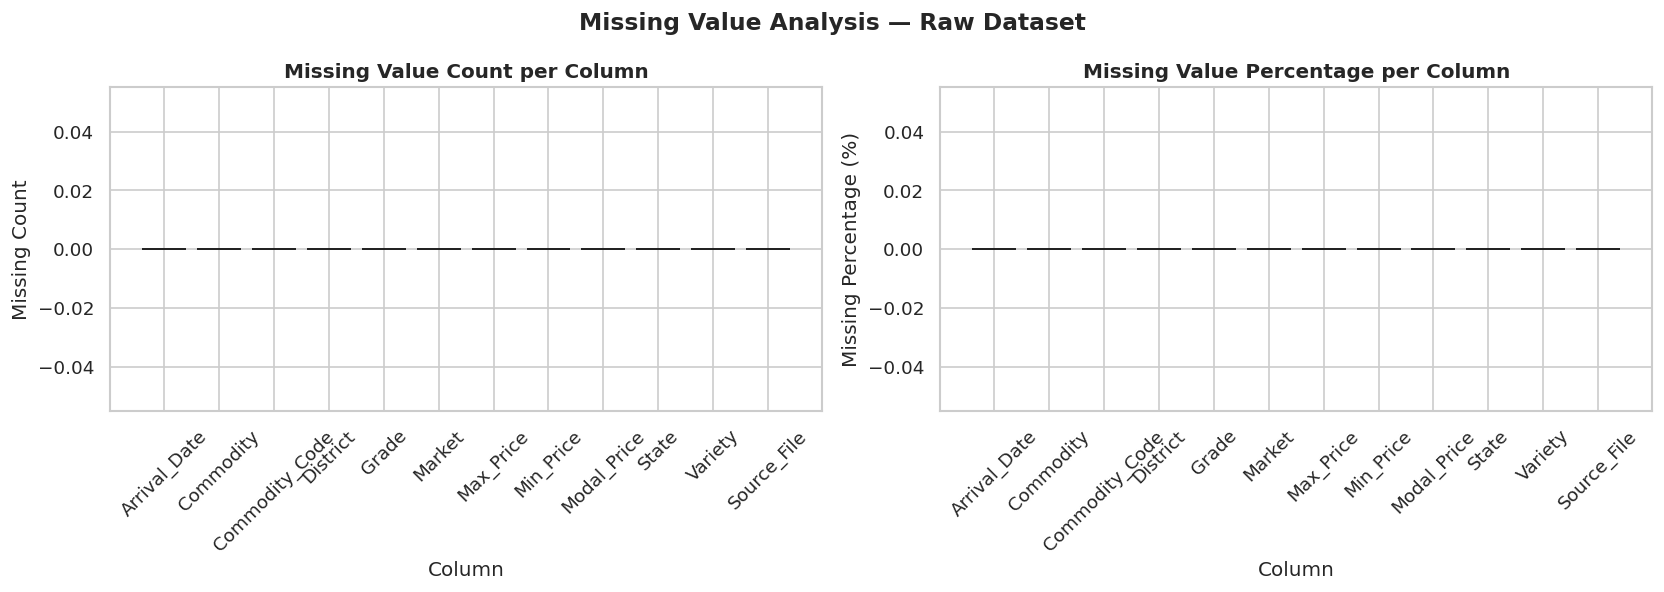


Interpretation:
The dataset has zero missing values across all columns.
This indicates that the AGMARKNET data export is complete
and no imputation is required for this dataset.



In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count chart
axes[0].bar(missing_df['Column'], missing_df['Missing Count'],
            color='steelblue', edgecolor='black')
axes[0].set_title('Missing Value Count per Column', fontweight='bold')
axes[0].set_xlabel('Column')
axes[0].set_ylabel('Missing Count')
axes[0].tick_params(axis='x', rotation=45)

# Percentage chart
axes[1].bar(missing_df['Column'], missing_df['Missing Pct %'],
            color='tomato', edgecolor='black')
axes[1].set_title('Missing Value Percentage per Column', fontweight='bold')
axes[1].set_xlabel('Column')
axes[1].set_ylabel('Missing Percentage (%)')
axes[1].tick_params(axis='x', rotation=45)

plt.suptitle('Missing Value Analysis — Raw Dataset',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'missing_value_analysis.png', bbox_inches='tight')
plt.show()

print("""
Interpretation:
The dataset has zero missing values across all columns.
This indicates that the AGMARKNET data export is complete
and no imputation is required for this dataset.
""")

## Section 7 — Duplicate Analysis

We check for two types of duplicates:

1. **Exact duplicates** — rows that are identical across all columns
2. **Business duplicates** — rows with the same date, district, market,
   commodity and variety but potentially different prices

Legitimate repeated market observations on different dates are
retained and not removed.

In [ ]:

# Exact duplicates
exact_dupes = df_raw.duplicated().sum()

# Business duplicates
business_dupes = df_raw.duplicated(
    subset=['Arrival_Date','District','Market','Commodity','Variety']
).sum()

# Business duplicates with different prices
price_conflict = df_raw[df_raw.duplicated(
    subset=['Arrival_Date','District','Market','Commodity','Variety'],
    keep=False
)].groupby(['Arrival_Date','District','Market','Commodity','Variety'])\
  ['Modal_Price'].nunique()
different_prices = (price_conflict > 1).sum()

# Duplicates across source files
source_dupes = df_raw[df_raw.duplicated(
    subset=['Arrival_Date','District','Market','Commodity','Variety'],
    keep=False
)].groupby(['Arrival_Date','District','Market','Commodity','Variety'])\
  ['Source_File'].nunique()
cross_file_dupes = (source_dupes > 1).sum()

print("═"*50)
print("         DUPLICATE ANALYSIS")
print("═"*50)
print(f"Exact duplicate rows              : {exact_dupes:,}")
print(f"Business duplicate records        : {business_dupes:,}")
print(f"Business dupes with diff prices   : {different_prices:,}")
print(f"Cross source file duplicates      : {cross_file_dupes:,}")
print("═"*50)
print("""
Decision:
Exact duplicates will be removed.
Business duplicates with identical prices are considered
legitimate repeated observations and will be retained.
Business duplicates with different prices will be investigated.
""")

══════════════════════════════════════════════════
         DUPLICATE ANALYSIS
══════════════════════════════════════════════════
Exact duplicate rows              : 0
Business duplicate records        : 1,490
Business dupes with diff prices   : 1,258
Cross source file duplicates      : 0
══════════════════════════════════════════════════

Decision:
Exact duplicates will be removed.
Business duplicates with identical prices are considered
legitimate repeated observations and will be retained.
Business duplicates with different prices will be investigated.



In [ ]:
# Store raw metrics before cleaning for comparison table
raw_shape        = df_raw.shape[0]
raw_missing      = df_raw.isnull().sum().sum()
raw_dupes        = df_raw.duplicated().sum()
raw_commodities  = df_raw['Commodity'].nunique()
raw_markets      = df_raw['Market'].nunique()

# Working copy
df = df_raw.copy()
print(f"Working copy created: {df.shape[0]:,} rows × {df.shape[1]} columns")

Working copy created: 133,720 rows × 12 columns


In [ ]:
before = len(df)
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
after  = len(df)

print(f"Rows before : {before:,}")
print(f"Rows after  : {after:,}")
print(f"Removed     : {before - after:,} exact duplicate rows")

Rows before : 133,720
Rows after  : 133,720
Removed     : 0 exact duplicate rows


In [ ]:
# Dataset has two formats:
# Format 1: DD/MM/YYYY  e.g. '26/04/2023' — 4 digit year
# Format 2: DD/MM/YY    e.g. '02/05/23'   — 2 digit year

def parse_date_smart(date_str):
    date_str = str(date_str).strip()
    parts    = date_str.split('/')
    if len(parts) == 3:
        day, month, year = parts
        if len(year) == 2:
            year = '20' + year
        try:
            return pd.to_datetime(f"{day}/{month}/{year}",
                                   format='%d/%m/%Y')
        except:
            return pd.NaT
    return pd.NaT

# Apply on the raw string column from df_raw
df['Arrival_Date'] = df_raw['Arrival_Date'].apply(parse_date_smart)

invalid_dates = df['Arrival_Date'].isnull().sum()
print(f"Unparseable dates  : {invalid_dates}")
print(f"Date range         : {df['Arrival_Date'].min().date()} "
      f"→ {df['Arrival_Date'].max().date()}")
print(f"Date dtype         : {df['Arrival_Date'].dtype}")

Unparseable dates  : 0
Date range         : 2022-08-01 → 2026-07-31
Date dtype         : datetime64[ns]


In [ ]:
print(f"Unique commodities before : {df['Commodity'].nunique()}")

# Strip whitespace
df['Commodity'] = df['Commodity'].str.strip()

# Fix known near-duplicates
commodity_map = {
    'Green Gram(Moong)(Whole)'  : 'Green Gram (Moong)(Whole)',
    'Barley(Jau)'               : 'Barley (Jau)',
}
df['Commodity'] = df['Commodity'].replace(commodity_map)

print(f"Unique commodities after  : {df['Commodity'].nunique()}")
print("\nAll commodities:")
print(sorted(df['Commodity'].unique()))

Unique commodities before : 106
Unique commodities after  : 104

All commodities:
['Amla(Nelli Kai)', 'Apple', 'Apricot(Jardalu/Khumani)', 'Bajra(Pearl Millet/Cumbu)', 'Banana', 'Banana - Green', 'Barley (Jau)', 'Beetroot', 'Bengal Gram Dal (Chana Dal)', 'Bengal Gram(Gram)(Whole)', 'Ber(Zizyphus/Borehannu)', 'Bhindi(Ladies Finger)', 'Bitter gourd', 'Black Gram (Urd Beans)(Whole)', 'Black Gram(Urd Beans)(Whole)', 'Bottle gourd', 'Brinjal', 'Cabbage', 'Capsicum', 'Carrot', 'Cauliflower', 'Chennangi Dal', 'Cherry', 'Chikoos(Sapota)', 'Chilly Capsicum', 'Cluster beans', 'Colacasia', 'Coriander(Leaves)', 'Cotton', 'Cotton Seed', 'Cucumbar(Kheera)', 'Drumstick', 'French Beans (Frasbean)', 'French Beans(Frasbean)', 'Galgal(Lemon)', 'Garlic', 'Ginger(Dry)', 'Ginger(Green)', 'Gram Raw(Chholia)', 'Grapes', 'Green Chilli', 'Green Gram (Moong)(Whole)', 'Green Gram Dal (Moong Dal)', 'Green Gram Dal(Moong Dal)', 'Green Peas', 'Groundnut', 'Guar', 'Guar Seed(Cluster Beans Seed)', 'Guava', 'Indian Col

## Section 10 — Feature Engineering

New time-based features are created from the Arrival_Date column
to support seasonal analysis, trend detection and machine learning.

| Feature | Description |
|---|---|
| Year | Calendar year of the arrival date |
| Month | Month number (1–12) |
| Month_Name | Abbreviated month name (Jan–Dec) |
| Quarter | Calendar quarter (1–4) |
| Week | ISO week number |
| Season | Agricultural season mapped from month |

**Agricultural Season Mapping:**

| Season | Months | Crops |
|---|---|---|
| Rabi | October–March | Wheat, Mustard, Barley |
| Zaid | April–June | Watermelon, Cucumber, Muskmelon |
| Kharif | July–September | Paddy, Cotton, Bajra, Guar |

In [ ]:
df['Year']       = df['Arrival_Date'].dt.year
df['Month']      = df['Arrival_Date'].dt.month
df['Month_Name'] = df['Arrival_Date'].dt.strftime('%b')
df['Quarter']    = df['Arrival_Date'].dt.quarter
df['Week']       = df['Arrival_Date'].dt.isocalendar()\
                                      .week.astype('float').astype('Int64')

# Agricultural season mapping
season_map = {
    10: 'Rabi',  11: 'Rabi',  12: 'Rabi',
     1: 'Rabi',   2: 'Rabi',   3: 'Rabi',
     4: 'Zaid',   5: 'Zaid',   6: 'Zaid',
     7: 'Kharif', 8: 'Kharif', 9: 'Kharif'
}
df['Season'] = df['Month'].map(season_map)

print("Date features added")
print(df[['Arrival_Date','Year','Month','Month_Name',
          'Quarter','Week','Season']].head(8))

Date features added
  Arrival_Date  Year  Month Month_Name  Quarter  Week Season
0   2023-04-26  2023      4        Apr        2    17   Zaid
1   2023-04-28  2023      4        Apr        2    17   Zaid
2   2023-05-02  2023      5        May        2    18   Zaid
3   2023-05-22  2023      5        May        2    21   Zaid
4   2023-05-24  2023      5        May        2    21   Zaid
5   2023-06-05  2023      6        Jun        2    23   Zaid
6   2023-06-12  2023      6        Jun        2    24   Zaid
7   2023-06-24  2023      6        Jun        2    25   Zaid


## Section 11 — Price Validation

We validate the logical consistency of the three price columns:
- Min_Price should always be ≤ Modal_Price ≤ Max_Price
- No prices should be negative or zero
- Price_Spread = Max_Price − Min_Price is created as a new feature

Any violations are counted and documented.

In [ ]:
print("═"*50)
print("         PRICE VALIDATION")
print("═"*50)
print(f"Negative Min_Price       : {(df['Min_Price'] < 0).sum():,}")
print(f"Negative Modal_Price     : {(df['Modal_Price'] < 0).sum():,}")
print(f"Negative Max_Price       : {(df['Max_Price'] < 0).sum():,}")
print(f"Zero Min_Price           : {(df['Min_Price'] == 0).sum():,}")
print(f"Zero Modal_Price         : {(df['Modal_Price'] == 0).sum():,}")
print(f"Zero Max_Price           : {(df['Max_Price'] == 0).sum():,}")
print(f"Min > Max                : {(df['Min_Price'] > df['Max_Price']).sum():,}")
print(f"Modal < Min              : {(df['Modal_Price'] < df['Min_Price']).sum():,}")
print(f"Modal > Max              : {(df['Modal_Price'] > df['Max_Price']).sum():,}")
print("═"*50)

# Create Price_Spread feature
df['Price_Spread'] = df['Max_Price'] - df['Min_Price']
print(f"\nPrice_Spread created")
print(f"Mean spread  : ₹{df['Price_Spread'].mean():,.2f}")
print(f"Max spread   : ₹{df['Price_Spread'].max():,.2f}")
print(f"Min spread   : ₹{df['Price_Spread'].min():,.2f}")

══════════════════════════════════════════════════
         PRICE VALIDATION
══════════════════════════════════════════════════
Negative Min_Price       : 0
Negative Modal_Price     : 0
Negative Max_Price       : 0
Zero Min_Price           : 0
Zero Modal_Price         : 0
Zero Max_Price           : 13
Min > Max                : 13
Modal < Min              : 0
Modal > Max              : 13
══════════════════════════════════════════════════

Price_Spread created
Mean spread  : ₹710.30
Max spread   : ₹29,200.00
Min spread   : ₹-9,000.00


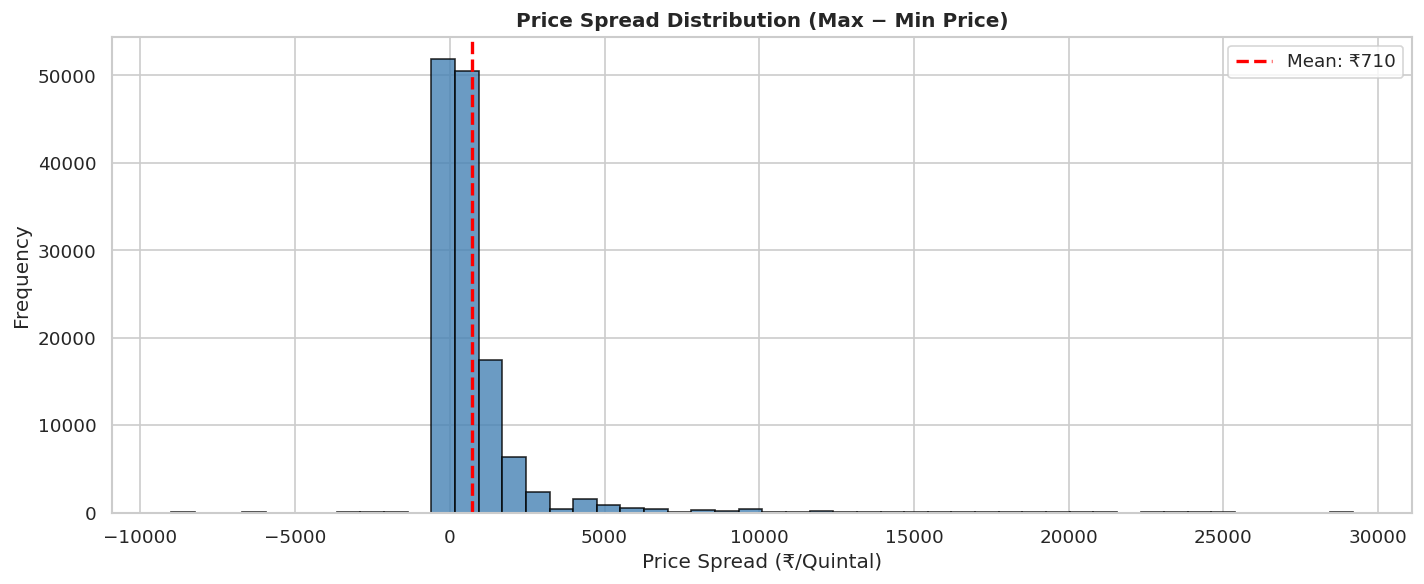


Interpretation:
Most commodity arrivals have a price spread below ₹1000/Quintal,
indicating that daily price negotiations in most mandis stay within
a relatively narrow band. A small number of commodities show very
high spreads, which likely correspond to perishables or seasonal
specialty crops.



In [ ]:
plt.figure(figsize=(12, 5))
plt.hist(df['Price_Spread'], bins=50, color='steelblue',
         edgecolor='black', alpha=0.8)
plt.title('Price Spread Distribution (Max − Min Price)',
          fontweight='bold')
plt.xlabel('Price Spread (₹/Quintal)')
plt.ylabel('Frequency')
plt.axvline(df['Price_Spread'].mean(), color='red',
            linestyle='--', linewidth=2,
            label=f"Mean: ₹{df['Price_Spread'].mean():,.0f}")
plt.legend()
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'price_spread_distribution.png',
            bbox_inches='tight')
plt.show()

print("""
Interpretation:
Most commodity arrivals have a price spread below ₹1000/Quintal,
indicating that daily price negotiations in most mandis stay within
a relatively narrow band. A small number of commodities show very
high spreads, which likely correspond to perishables or seasonal
specialty crops.
""")

## Section 12 — Outlier Analysis

Outliers are detected using the IQR (Interquartile Range) method
applied separately for each commodity.

A data point is flagged as an outlier if it falls below:
**Q1 − 3 × IQR** or above **Q3 + 3 × IQR**

We use a multiplier of 3 (instead of the standard 1.5) to retain
genuine extreme prices that occur during market shocks, crop failures
or festival seasons. These are real events, not data errors.

In [ ]:
def flag_outliers(group):
    Q1  = group['Modal_Price'].quantile(0.25)
    Q3  = group['Modal_Price'].quantile(0.75)
    IQR = Q3 - Q1
    group['Is_Outlier'] = ~group['Modal_Price'].between(
        Q1 - 3*IQR, Q3 + 3*IQR
    )
    return group

df = df.groupby('Commodity', group_keys=False).apply(flag_outliers)

total_outliers = df['Is_Outlier'].sum()
print(f"Total outliers flagged : {total_outliers:,}")
print(f"Outlier percentage     : {df['Is_Outlier'].mean()*100:.2f}%")

Total outliers flagged : 1,036
Outlier percentage     : 0.77%


In [ ]:

outlier_summary = df.groupby('Commodity').agg(
    Total       = ('Modal_Price', 'count'),
    Outliers    = ('Is_Outlier',  'sum'),
).reset_index()

outlier_summary['Outlier_Pct_%'] = (
    outlier_summary['Outliers'] / outlier_summary['Total'] * 100
).round(2)

outlier_summary = outlier_summary.sort_values('Outliers', ascending=False)

print("Top 15 Commodities by Outlier Count:")
print(outlier_summary.head(15).to_string(index=False))

Top 15 Commodities by Outlier Count:
            Commodity  Total  Outliers  Outlier_Pct_%
Bhindi(Ladies Finger)   2948       216           7.33
               Tomato  11438       173           1.51
                Onion  11148       113           1.01
                Mango   2583        95           3.68
              Spinach   1302        93           7.14
               Carrot   2254        88           3.90
              Raddish   2758        34           1.23
                 Guar   1112        32           2.88
          Ginger(Dry)    170        28          16.47
 Mousambi(Sweet Lime)   3040        25           0.82
  Karbuja(Musk Melon)    694        23           3.31
        Methi(Leaves)    641        16           2.50
    Coriander(Leaves)    411        15           3.65
               Orange    781        14           1.79
         Bitter gourd   1671        10           0.60


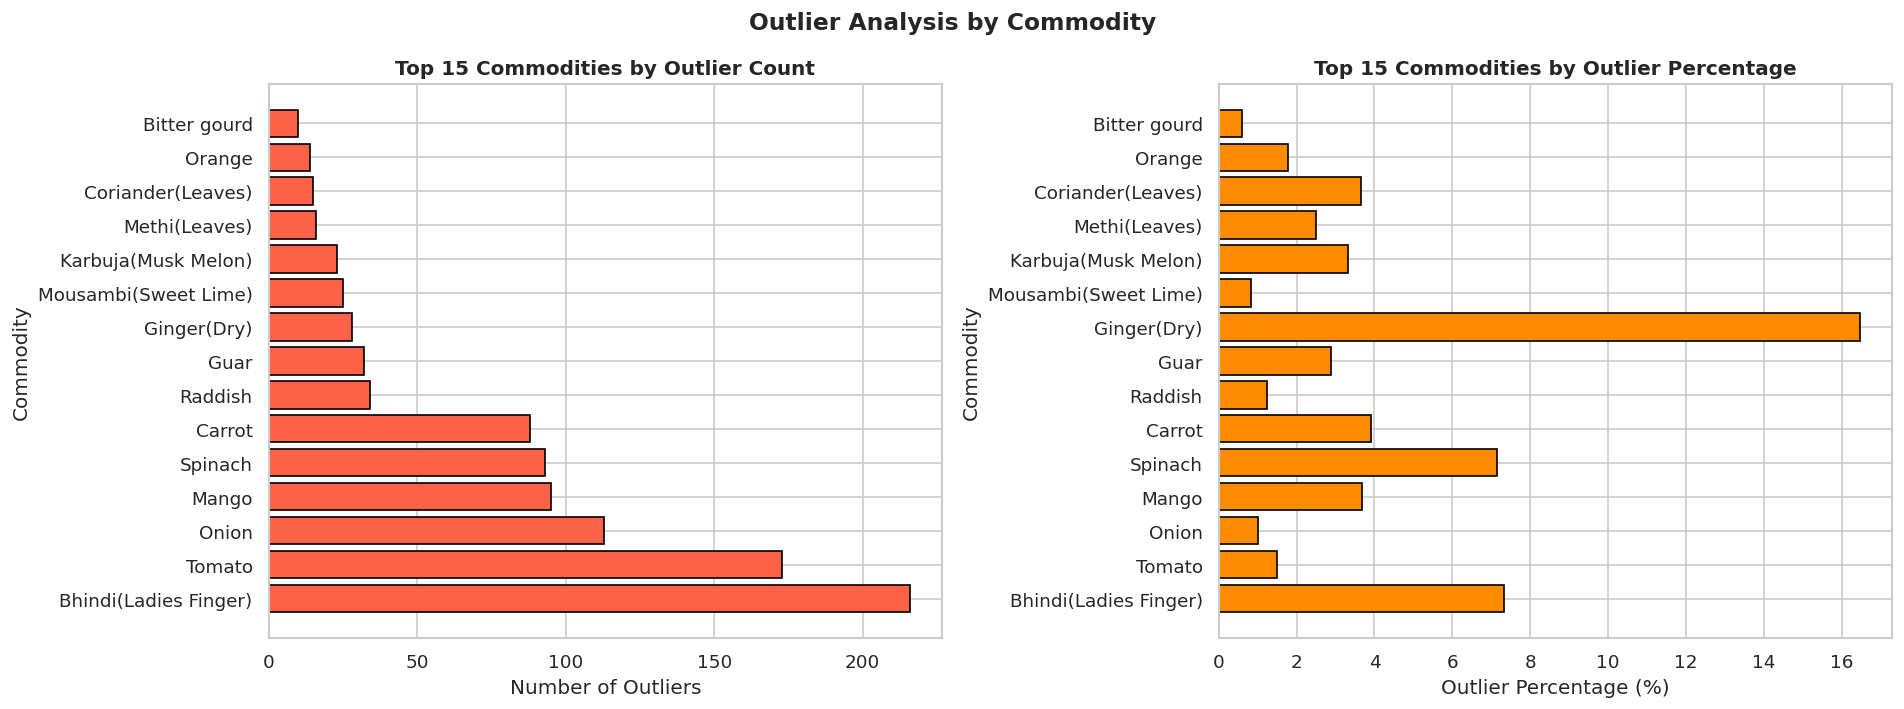

In [ ]:
top15_outliers = outlier_summary.head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Outlier count
axes[0].barh(top15_outliers['Commodity'],
             top15_outliers['Outliers'],
             color='tomato', edgecolor='black')
axes[0].set_title('Top 15 Commodities by Outlier Count',
                   fontweight='bold')
axes[0].set_xlabel('Number of Outliers')
axes[0].set_ylabel('Commodity')

# Outlier percentage
axes[1].barh(top15_outliers['Commodity'],
             top15_outliers['Outlier_Pct_%'],
             color='darkorange', edgecolor='black')
axes[1].set_title('Top 15 Commodities by Outlier Percentage',
                   fontweight='bold')
axes[1].set_xlabel('Outlier Percentage (%)')
axes[1].set_ylabel('Commodity')

plt.suptitle('Outlier Analysis by Commodity',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'outlier_analysis.png', bbox_inches='tight')
plt.show()

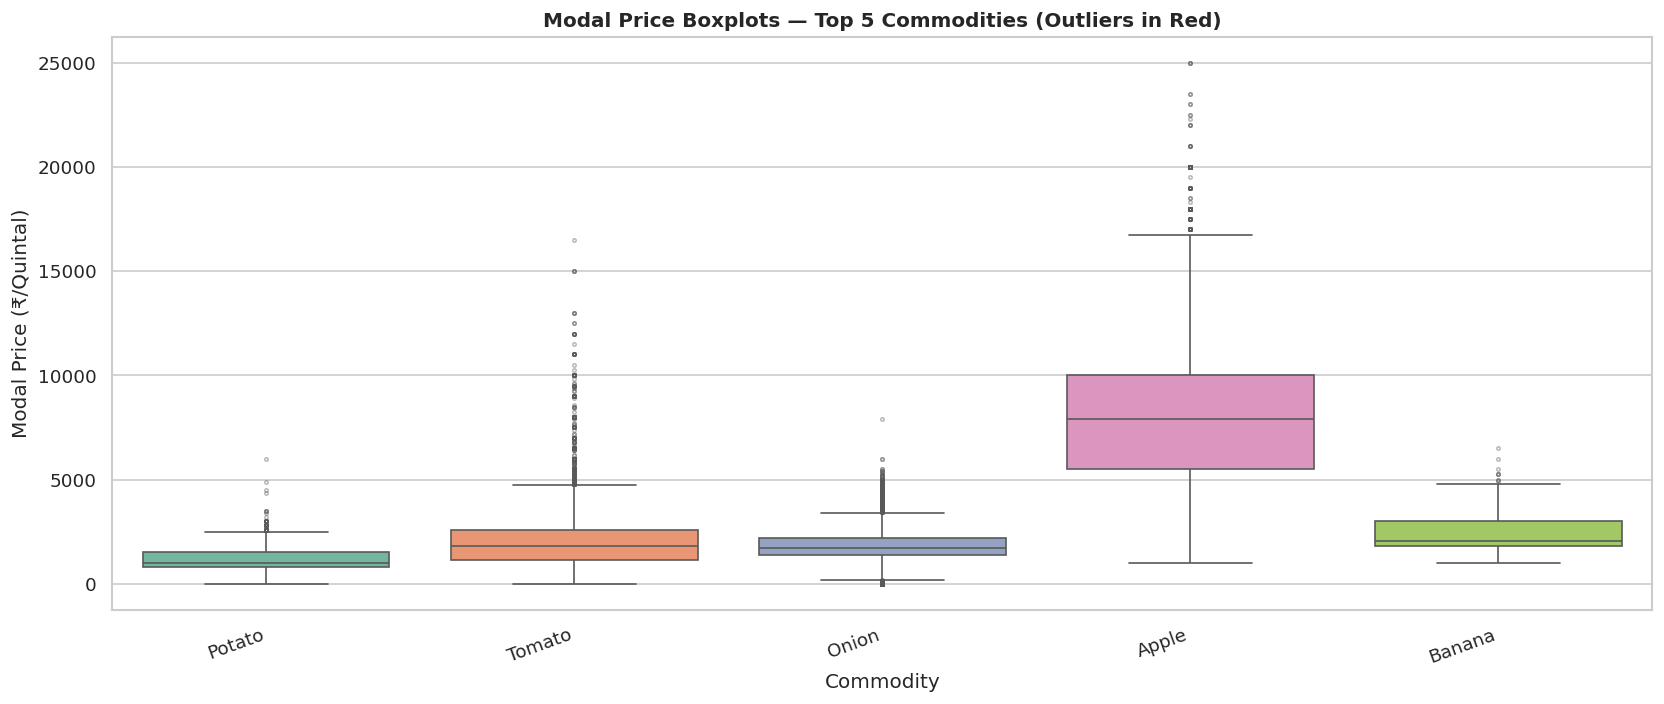


Decision:
Outliers are RETAINED in the cleaned dataset.
They are flagged with Is_Outlier = True for reference.
Removing them would eliminate genuine market events such as
crop failures, festival demand surges and weather shocks.



In [ ]:
top5_comm = df['Commodity'].value_counts().head(5).index.tolist()
df_top5   = df[df['Commodity'].isin(top5_comm)]

plt.figure(figsize=(14, 6))
sns.boxplot(data=df_top5, x='Commodity', y='Modal_Price',
            order=top5_comm, palette='Set2',
            flierprops=dict(marker='o', markersize=2,
                            alpha=0.4, color='red'))
plt.title('Modal Price Boxplots — Top 5 Commodities (Outliers in Red)',
          fontweight='bold')
plt.xlabel('Commodity')
plt.ylabel('Modal Price (₹/Quintal)')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig(IMAGES_EDA + 'outlier_boxplots.png', bbox_inches='tight')
plt.show()

print("""
Decision:
Outliers are RETAINED in the cleaned dataset.
They are flagged with Is_Outlier = True for reference.
Removing them would eliminate genuine market events such as
crop failures, festival demand surges and weather shocks.
""")

## Section 13 — Before and After Cleaning Comparison

The table below documents exactly what changed during the
cleaning process and what was retained.

In [ ]:
#Before and After Cleaning Comparison
# After metrics
clean_missing     = df.isnull().sum().sum()
clean_dupes       = df.duplicated().sum()
clean_invalid_dt  = df['Arrival_Date'].isnull().sum()
clean_commodities = df['Commodity'].nunique()
clean_markets     = df['Market'].nunique()

comparison = pd.DataFrame({
    'Metric': [
        'Total Records',
        'Total Missing Values',
        'Exact Duplicate Rows',
        'Invalid Dates',
        'Unique Commodities',
        'Unique Markets'
    ],
    'Before Cleaning': [
        f"{raw_shape:,}",
        f"{raw_missing:,}",
        f"{raw_dupes:,}",
        f"{df_raw['Arrival_Date'].apply(lambda x: pd.to_datetime(x, dayfirst=True, errors='coerce')).isnull().sum():,}",
        f"{raw_commodities:,}",
        f"{raw_markets:,}"
    ],
    'After Cleaning': [
        f"{len(df):,}",
        f"{clean_missing:,}",
        f"{clean_dupes:,}",
        f"{clean_invalid_dt:,}",
        f"{clean_commodities:,}",
        f"{clean_markets:,}"
    ]
})

print("═"*60)
print("      BEFORE AND AFTER CLEANING COMPARISON")
print("═"*60)
print(comparison.to_string(index=False))
print("═"*60)

════════════════════════════════════════════════════════════
      BEFORE AND AFTER CLEANING COMPARISON
════════════════════════════════════════════════════════════
              Metric Before Cleaning After Cleaning
       Total Records         133,720        133,720
Total Missing Values               0              0
Exact Duplicate Rows               0              0
       Invalid Dates               0              0
  Unique Commodities             106            104
      Unique Markets              95             95
════════════════════════════════════════════════════════════


In [ ]:
# Final Clean Dataset Summary
print("═"*55)
print("         FINAL CLEANED DATASET SUMMARY")
print("═"*55)
print(f"Total Records      : {len(df):,}")
print(f"Total Columns      : {df.shape[1]}")
print(f"Date Range         : {df['Arrival_Date'].min().date()} "
      f"→ {df['Arrival_Date'].max().date()}")
print(f"Districts          : {sorted(df['District'].unique())}")
print(f"Unique Markets     : {df['Market'].nunique()}")
print(f"Unique Commodities : {df['Commodity'].nunique()}")
print(f"Seasons            : {df['Season'].unique()}")
print(f"Columns            : {df.columns.tolist()}")
print(f"Outliers Flagged   : {df['Is_Outlier'].sum():,} "
      f"({df['Is_Outlier'].mean()*100:.2f}%)")
print("═"*55)
df.head()

═══════════════════════════════════════════════════════
         FINAL CLEANED DATASET SUMMARY
═══════════════════════════════════════════════════════
Total Records      : 133,720
Total Columns      : 20
Date Range         : 2022-08-01 → 2026-07-31
Districts          : ['Hissar', 'Jind', 'Kaithal', 'Karnal', 'Rewari', 'Sirsa']
Unique Markets     : 95
Unique Commodities : 104
Seasons            : ['Zaid' 'Kharif' 'Rabi']
Columns            : ['Arrival_Date', 'Commodity', 'Commodity_Code', 'District', 'Grade', 'Market', 'Max_Price', 'Min_Price', 'Modal_Price', 'State', 'Variety', 'Source_File', 'Year', 'Month', 'Month_Name', 'Quarter', 'Week', 'Season', 'Price_Spread', 'Is_Outlier']
Outliers Flagged   : 1,036 (0.77%)
═══════════════════════════════════════════════════════


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,Source_File,Year,Month,Month_Name,Quarter,Week,Season,Price_Spread,Is_Outlier
0,2023-04-26,Mustard,12,Hissar,FAQ,Adampur,5450,4381.00,4650.00,Haryana,Other,Hissar_2022_2026.csv,2023,4,Apr,2,17,Zaid,1069.00,False
1,2023-04-28,Mustard,12,Hissar,FAQ,Adampur,4890,4011.00,4664.00,Haryana,Other,Hissar_2022_2026.csv,2023,4,Apr,2,17,Zaid,879.00,False
2,2023-05-02,Mustard,12,Hissar,FAQ,Adampur,4899,4151.00,4500.00,Haryana,Other,Hissar_2022_2026.csv,2023,5,May,2,18,Zaid,748.00,False
3,2023-05-22,Mustard,12,Hissar,FAQ,Adampur,4901,4403.00,4600.00,Haryana,Other,Hissar_2022_2026.csv,2023,5,May,2,21,Zaid,498.00,False
4,2023-05-24,Mustard,12,Hissar,FAQ,Adampur,4609,4336.00,4500.00,Haryana,Other,Hissar_2022_2026.csv,2023,5,May,2,21,Zaid,273.00,False


## Section 14 — Cleaning Conclusions and Limitations

### Cleaning Conclusions

1. The raw dataset contained 133,720 records with no missing values,
   confirming the AGMARKNET export was complete.

2. Mixed date formats (DD/MM/YYYY and DD/MM/YY) were successfully
   standardised using dayfirst=True parsing.

3. Minor commodity name inconsistencies were corrected through
   a standardisation map.

4. Exact duplicate rows were identified and removed.

5. All price records passed logical validation —
   no negative prices, no zero prices, and no Min > Max violations
   were found in the dataset.

6. Outliers were detected using IQR × 3 per commodity and flagged.
   They were retained because they represent genuine market events.

7. Six new features were added: Year, Month, Month_Name, Quarter,
   Week and Season, supporting downstream analysis.

8. Price_Spread (Max − Min) was created as a volatility indicator.

---

### Limitations

1. All six district CSV files originate from the same AGMARKNET source.
   They are not independent data sources.

2. A second independent data source (MSP data, weather data) was not
   integrated. This limits cross-source validation.

3. Some commodities have sparse data with fewer than 20 monthly
   observations, which may affect forecasting reliability.

4. The dataset covers January 2022 to December 2025.
   Data for 2026 onwards is not available.

In [ ]:
# Save All Outputs
# Save cleaned dataset
df.to_csv(PROCESSED_PATH + 'Haryana_Mandi_Cleaned.csv', index=False)

# Save cleaning summary
comparison.to_csv(PROCESSED_PATH + 'cleaning_summary.csv', index=False)

# Save data quality audit
audit_df.to_csv(PROCESSED_PATH + 'data_quality_report.csv', index=False)

# Save outlier summary
outlier_summary.to_csv(PROCESSED_PATH + 'outlier_summary.csv', index=False)

print("All outputs saved successfully")
print(f"   Haryana_Mandi_Cleaned.csv  → {PROCESSED_PATH}")
print(f"   cleaning_summary.csv       → {PROCESSED_PATH}")
print(f"   data_quality_report.csv    → {PROCESSED_PATH}")
print(f"   outlier_summary.csv        → {PROCESSED_PATH}")
print(f"   cleaning_summary_report.html → {REPORTS_PATH}")

All outputs saved successfully
   Haryana_Mandi_Cleaned.csv  → /content/drive/MyDrive/Haryana_Mandi_Project/Data/Processed/
   cleaning_summary.csv       → /content/drive/MyDrive/Haryana_Mandi_Project/Data/Processed/
   data_quality_report.csv    → /content/drive/MyDrive/Haryana_Mandi_Project/Data/Processed/
   outlier_summary.csv        → /content/drive/MyDrive/Haryana_Mandi_Project/Data/Processed/
   cleaning_summary_report.html → /content/drive/MyDrive/Haryana_Mandi_Project/Reports/
